John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

# Candidate-level match model: conditional logit with 60 s window and distance-weighted neighbour features

This is the conditional-logit version of notebook 06. It keeps notebook 06's structure: one row per (event, candidate song type), exactly one chosen song type per event, the **same train/test split and CV folds** (same seed and same `rsample` calls, so the same held-out events as the random forest), prediction by ranking the candidates inside each event, and the same ranking metrics.

**Model.** For event *e* and candidate song type *j*,

P(j chosen in e) = exp(α<sub>j</sub> + x<sub>ej</sub>·β) / Σ<sub>k in e</sub> exp(α<sub>k</sub> + x<sub>ek</sub>·β)

The likelihood is conditioned on each choice set, which is the conditional logit of the [mclogit vignette](https://cran.rstudio.com/web/packages/mclogit/vignettes/conditional-logit.html). It is fitted with an analytic gradient and BFGS plus a small ridge penalty (see "Why not call `mclogit()`" below).

**Consequence for the predictors.** In a conditional logit anything that is identical for every candidate of an event cancels out of the likelihood. So the notebook-06 inputs that are event-level constants (the per-song-type window counts `n_ust_<t>_window`, `focal_last_k_ust` as a lone factor, `focal_time_since_last_k`) cannot be used as they are. They are re-expressed as **candidate-aligned** features, each looked up for the candidate it describes:

| Feature group | Columns | Meaning |
|---|---|---|
| Candidate intercept | `α_j` | Base rate of each song type (replaces `candidate_ust`). |
| `own_repeat` | `cand_repeats_own_last_k` | 1 if the candidate equals the focal male's k-th last song. |
| `own_repeat_time` | `cand_repeat_x_logtime_k` | The repeat flag × log(1 + seconds since that song). This is how time-since-own-song enters. |
| `own_transition` | `cand_trans_own_k` | Smoothed log P(candidate \| own k-th last song), estimated from the training events only (leave-one-event-out for the events that build the counts, so there is no self-leakage). |
| `cand_count_unw` | `cand_n_songs_unweighted` | Neighbour songs of the candidate's type in the last 60 s. |
| `cand_count_wtd` | `cand_n_songs_weighted` | The same count with each song weighted by the singer's distance to the focal male. |
| `cand_last_wtd` | `cand_nbr_last_k_weighted` | Summed distance weights of neighbours whose k-th most recent song is the candidate's type. |

The final cells export one `<model name>_song_accuracies.csv` per model (columns `ID, UST, estimated_accuracy, model, n`) and one `<model name>_test_accuracies.csv` per model with overall held-out accuracy per male (columns `ID, estimated_accuracy, model, n`). Everything else stays in memory. OPR is excluded (`EXCLUDE_IDS`).

**Training happens in exactly one cell**, the ablation cell. Every other cell loads data, defines functions, or summarises and plots results.

**Why not call `mclogit()`?** `mclogit` is fitted by IRLS and has no penalty. With about 20–30 song types per male, some song types are never chosen in a training set, which gives infinite coefficients. A penalised direct fit also avoids refitting a general-purpose routine for every fold, λ and model. Set `VERIFY_WITH_MCLOGIT <- TRUE` in the Settings cell to check that the implementation reproduces `mclogit()` on an unpenalised model.

**Speed.** Features are built once per male as `events × song types` matrices. Fold features are built once and shared by all models. Each fit is a few matrix products per BFGS step, and λ is warm-started. Males are fitted in parallel. There are no trees and no tidymodels recipes.

**Errors found in notebook 06 (fixed here).**

1. The overview table always showed `n_weighted_cols = 0`, because `attr(., "weighted_cols")` was never set. The weighted columns were being used, only the count was wrong.
2. The tuning markdown said "roughly 70 predictors"; the output shows 119–194.
3. The baseline cell wrote a CSV to `RESULTS_DIR` before `dir.create()` had run (that was in the save cell), which fails on a fresh checkout. The directory is now created in Settings.
4. There were two ablation cells that both defined `abl_*`, `fold_idx`, `ablation_results` and `WINDOW_COUNTS_AS_FACTOR`, so the second silently overwrote the first. In the first, `baseline` meant "own history"; in the baseline cell it meant "most common song"; a patch cell renamed things afterwards, so the saved CSVs used inconsistent names. Now there is one ablation cell, and `baseline` always means most common song.
5. The patch cell appended baseline rows without `random_baseline`, `n_used` or `dropped`, leaving NAs.
6. The main RF fit was repeated, with fewer predictors, inside the ablation. The main fit has been removed, as requested.

Not changed, but worth knowing: events are split at random, and the 60 s windows of neighbouring events overlap heavily, so test events are not independent of training events. This inflates every model's absolute accuracy, not the comparisons between models. The split is kept so results stay comparable with the random forest. A split by recording day would be the stricter test.

Import Packages

In [1]:
# data.table is loaded first so that dplyr's first()/last()/between() take precedence
library(data.table)
library(tidyverse)
library(rsample)   # only for the train/test split and CV folds (identical to notebook 06)
library(furrr)
set.seed(42)

Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'tidyverse' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'tibble' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'readr' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'lubridate' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::between()     masks data.ta

Settings

In [2]:
MODEL_NAME    <- "candidate_match_clogit_distance_weighted_window60"
RF_MODEL_NAME <- "candidate_match_distance_weighted_window60"   # notebook 06 (random forest) results, for comparison

CANDIDATE_DIR <- "data/by_id"
RESULTS_DIR   <- "data/2026_results"
dir.create(RESULTS_DIR, recursive = TRUE, showWarnings = FALSE)

# Focal males left out of modelling (OPR has no close neighbours, so it cannot show neighbour influence)
EXCLUDE_IDS <- c("OPR")

# Own-song history lags (as in notebook 06)
OWN_LAGS <- 1:2

# TRUE: drop every event that has an NA in any predictor column (keeps exactly one match per event);
# this reproduces notebook 06's events and therefore its split.
# FALSE: keep those events; missing counts become 0, missing times the median, missing previous songs "unknown".
DROP_NA_EVENTS <- TRUE

# Split / CV (same values as notebook 06)
TRAIN_PROP <- 0.7
CV_FOLDS   <- 5

# Ridge strength on the mean negative log-likelihood, strongest first. Ties in CV go to the strongest penalty.
LAMBDA_GRID <- c(1e-1, 3e-2, 1e-2, 3e-3, 1e-3, 1e-4)

# What lambda is tuned on: "log_lik" (mean held-out log-likelihood of the chosen song type, smooth and stable)
# or "top1" (top-1 accuracy, as in notebook 06).
TUNE_METRIC <- "log_lik"

# Additive smoothing for the own-song transition feature log P(candidate | previous own song)
TRANSITION_ALPHA <- 1

# "none": neighbour counts as they are; "log1p": log(1 + count), i.e. diminishing returns
COUNT_TRANSFORM <- "none"

# Model whose predictions are shown in the confusion matrices and coefficient plot
FINAL_MODEL <- "aligned_all"

# TRUE: also fit one small unpenalised model with mclogit::mclogit() and compare coefficients (needs the mclogit package)
VERIFY_WITH_MCLOGIT <- FALSE

N_WORKERS <- max(1, parallel::detectCores() - 1)

Load candidate-level data and build candidate-aligned feature matrices (the window and weighted columns are already in the candidate files)

In [3]:
candidate_files <- list.files(CANDIDATE_DIR, pattern = "_candidate_classification\\.csv$", full.names = TRUE)
if (length(candidate_files) == 0) stop("No *_candidate_classification.csv files found in ", CANDIDATE_DIR)

# To test only a single classifier, uncomment the next line:
# candidate_files <- candidate_files[1]

# Column selection rules are the same as in notebook 06
select_window_cols <- function(col_names) {
    has_window <- str_detect(col_names, regex("window", ignore_case = TRUE))
    excluded   <- str_detect(col_names, regex("target|others", ignore_case = TRUE)) |
                  str_starts(col_names, "candidate_")
    col_names[has_window & !excluded]
}
select_weighted_cols <- function(col_names) {
    col_names[str_detect(col_names, "_wtd$|^n_(songs|singers)_last[0-9]+s$")]
}
# Only these columns are read from disk (fread's select = ... is much faster than reading everything)
needed_columns <- function(col_names) {
    col_names[col_names %in% c("ID", "event_id", "candidate_ust", "match", "male_number") |
              str_detect(col_names, regex("window", ignore_case = TRUE)) |
              str_detect(col_names, "_wtd$|^n_(songs|singers)_last[0-9]+s$") |
              str_detect(col_names, "^M[0-9]+_[0-9]+_last_UST$|^time_since_M[0-9]+_[0-9]+_last_song$")]
}

# One focal male -> a "design": events x song-type matrices of candidate-aligned features.
# Layout: row = event, column = song type (slot). `mask` marks the candidates that exist in each event.
build_male_design <- function(song_data, id_value, number_value, source_name) {
    male_prefix   <- paste0("M", number_value)
    own_type_cols <- paste0(male_prefix, "_", OWN_LAGS, "_last_UST")
    own_time_cols <- paste0("time_since_", male_prefix, "_", OWN_LAGS, "_last_song")
    window_cols   <- select_window_cols(names(song_data))
    weighted_cols <- select_weighted_cols(names(song_data))

    missing_columns <- setdiff(c("event_id", "candidate_ust", "match", own_type_cols, own_time_cols), names(song_data))
    if (length(missing_columns) > 0) {
        stop(sprintf("Missing required columns in %s for %s: %s", source_name, male_prefix,
                     paste(missing_columns, collapse = ", ")))
    }
    if (length(window_cols) == 0)   stop(sprintf("No window columns found in %s.", source_name))
    if (length(weighted_cols) == 0) stop(sprintf("No distance-weighted columns found in %s. Re-run notebook 02.", source_name))

    md <- song_data[as.character(male_number) == number_value]

    # Drop events with an NA in any predictor column (same columns as notebook 06)
    na_cols         <- c(window_cols, weighted_cols, own_type_cols, own_time_cols, "candidate_ust")
    n_events_before <- uniqueN(md$event_id)
    if (DROP_NA_EVENTS) {
        row_has_na <- rowSums(is.na(md[, ..na_cols])) > 0
        bad_events <- unique(md$event_id[row_has_na])
        if (length(bad_events) > 0) md <- md[which(!(md$event_id %in% bad_events))]
    }
    if (nrow(md) == 0) stop(sprintf("No events left for %s_%s in %s", id_value, male_prefix, source_name))

    # Events in order of first appearance; song types in numeric order
    event_ids <- unique(md$event_id)
    ev    <- match(md$event_id, event_ids)
    types <- sort(unique(md$candidate_ust))
    ty    <- match(md$candidate_ust, types)
    n <- length(event_ids); K <- length(types)

    n_cand  <- tabulate(ev, nbins = n)
    n_match <- tabulate(ev[md$match == 1], nbins = n)
    if (any(n_cand < 2) || any(n_match != 1)) {
        stop(sprintf("Invalid candidate events for %s_%s in %s", id_value, male_prefix, source_name))
    }

    idx <- cbind(ev, ty)
    to_mat <- function(v) { M <- matrix(0, n, K); M[idx] <- v; M }
    mask <- matrix(FALSE, n, K); mask[idx] <- TRUE
    chosen <- integer(n); is_match <- md$match == 1
    chosen[ev[is_match]] <- ty[is_match]

    # Focal male's own history (event-level): previous song types as slot indices (NA if outside the repertoire)
    first_row <- !duplicated(ev)
    prev <- lapply(own_type_cols, function(cn) match(as.numeric(md[[cn]][first_row]), types))
    tsince <- lapply(own_time_cols, function(cn) {
        x <- as.numeric(md[[cn]][first_row]); x[is.na(x)] <- median(x, na.rm = TRUE); x
    })

    # Value of a per-song-type column for the candidate on each row
    pick_by_candidate <- function(cols, col_types) {
        j  <- match(md$candidate_ust, col_types)
        ok <- !is.na(j)
        W  <- as.matrix(md[, ..cols])
        out <- numeric(nrow(md))
        out[ok] <- W[cbind(which(ok), j[ok])]
        out[is.na(out)] <- 0
        out
    }
    tf <- if (COUNT_TRANSFORM == "log1p") log1p else identity

    static <- list()
    for (k in seq_along(OWN_LAGS)) {
        rep_k <- matrix(seq_len(K), n, K, byrow = TRUE) == prev[[k]]   # prev[[k]] recycles down the rows
        rep_k[is.na(rep_k)] <- FALSE
        static[[paste0("cand_repeats_own_last_", OWN_LAGS[k])]] <- rep_k * 1
        static[[paste0("cand_repeat_x_logtime_", OWN_LAGS[k])]] <- (rep_k * 1) * log1p(tsince[[k]])
    }

    unw_cols <- str_subset(names(md), "^n_ust_[0-9]+_window$")
    wtd_cols <- str_subset(names(md), "^n_ust_[0-9]+_last[0-9]+s_wtd$")
    if (length(unw_cols) == 0 || length(wtd_cols) == 0) stop("Unweighted or distance-weighted song count columns not found.")
    static$cand_n_songs_unweighted <- to_mat(tf(pick_by_candidate(unw_cols, as.numeric(str_match(unw_cols, "^n_ust_([0-9]+)_")[, 2]))))
    static$cand_n_songs_weighted   <- to_mat(tf(pick_by_candidate(wtd_cols, as.numeric(str_match(wtd_cols, "^n_ust_([0-9]+)_")[, 2]))))

    nbr_cols <- str_subset(names(md), "^nbr_last_[0-9]+_ust_[0-9]+_wtd$")
    if (length(nbr_cols) == 0) stop("No nbr_last_<k>_ust_<t>_wtd columns found.")
    nbr_m <- str_match(nbr_cols, "^nbr_last_([0-9]+)_ust_([0-9]+)_wtd$")
    for (k in sort(unique(as.integer(nbr_m[, 2])))) {
        sel <- which(as.integer(nbr_m[, 2]) == k)
        static[[paste0("cand_nbr_last_", k, "_weighted")]] <-
            to_mat(tf(pick_by_candidate(nbr_cols[sel], as.numeric(nbr_m[sel, 3]))))
    }

    list(focal_male = paste0(id_value, "_", male_prefix), focal_id = id_value, male_number = number_value,
         n = n, K = K, types = types, event_ids = event_ids, mask = mask, chosen = chosen,
         prev = prev, static = static,
         n_events_dropped_na = n_events_before - n, n_candidate_rows = nrow(md),
         n_window_cols = length(window_cols), n_weighted_cols = length(weighted_cols),
         # event_id only, in the same row order as notebook 06's candidate data (needed to reproduce its split)
         split_frame = tibble(event_id = md$event_id))
}

designs <- list_flatten(map(candidate_files, function(candidate_file) {
    header    <- names(fread(candidate_file, nrows = 0))
    song_data <- fread(candidate_file, select = needed_columns(header), integer64 = "double")
    focal_ids     <- unique(song_data$ID)
    if (all(focal_ids %in% EXCLUDE_IDS)) return(list())
    focal_numbers <- unique(as.character(song_data$male_number))
    focal_numbers <- focal_numbers[!is.na(focal_numbers)]
    if (length(focal_ids) != 1 || length(focal_numbers) == 0) {
        stop(sprintf("Expected one focal ID and at least one male_number in %s", candidate_file))
    }
    map(focal_numbers, function(focal_number) build_male_design(song_data, focal_ids, focal_number, candidate_file))
}))
names(designs) <- map_chr(designs, "focal_male")

In [4]:
# Overview of the candidate data actually used for modelling
map_dfr(designs, ~ tibble(
    focal_male          = .x$focal_male,
    n_events            = .x$n,
    n_events_dropped_na = .x$n_events_dropped_na,
    n_candidate_rows    = .x$n_candidate_rows,
    n_song_types        = .x$K,
    n_window_cols       = .x$n_window_cols,
    n_weighted_cols     = .x$n_weighted_cols,
    n_static_features   = length(.x$static)
))

focal_male,n_events,n_events_dropped_na,n_candidate_rows,n_song_types,n_window_cols,n_weighted_cols,n_static_features
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
DgTbO_M5,1157,10,32396,28,101,88,8
DgTbO_M6,989,10,27692,28,101,88,8
KLgK_M5,508,8,9652,19,59,61,8
KRDg_M2,1011,10,26286,26,59,82,8
LbOW_M1,689,10,12402,18,65,58,8
RbDgY_M2,650,6,13650,21,65,67,8
RRO_M6,525,10,9975,19,65,61,8
TbTbLg_M4,724,10,13756,19,65,61,8
TbWY_M1,594,10,10098,17,59,55,8


In [5]:
# Sanity check: candidate-aligned features of the first male, and their raw signal.
# An informative feature should have a clearly higher mean on the true match than on the other candidates.
first_design <- designs[[1]]
cat("Candidate-aligned features for", first_design$focal_male, ":\n")
print(names(first_design$static))

signal <- map_dfr(designs, function(D) {
    is_chosen <- matrix(FALSE, D$n, D$K); is_chosen[cbind(seq_len(D$n), D$chosen)] <- TRUE
    other <- D$mask & !is_chosen
    imap_dfr(D$static, function(M, feature) {
        tibble(feature = feature, sum_match = sum(M[is_chosen]), n_match = sum(is_chosen),
               sum_other = sum(M[other]), n_other = sum(other))
    })
}) %>%
    group_by(feature) %>%
    summarise(mean_on_true_match = sum(sum_match) / sum(n_match),
              mean_on_others     = sum(sum_other) / sum(n_other), .groups = "drop") %>%
    mutate(ratio = mean_on_true_match / mean_on_others)
print(signal, n = Inf)

Candidate-aligned features for DgTbO_M5 :
[1] "cand_repeats_own_last_1"  "cand_repeat_x_logtime_1" 
[3] "cand_repeats_own_last_2"  "cand_repeat_x_logtime_2" 
[5] "cand_n_songs_unweighted"  "cand_n_songs_weighted"   
[7] "cand_nbr_last_1_weighted" "cand_nbr_last_2_weighted"
# A tibble: 8 × 4
  feature                  mean_on_true_match mean_on_others ratio
  <chr>                                 <dbl>          <dbl> <dbl>
1 cand_n_songs_unweighted              1.16           0.549   2.12
2 cand_n_songs_weighted                0.856          0.398   2.15
3 cand_nbr_last_1_weighted             0.246          0.0651  3.78
4 cand_nbr_last_2_weighted             0.151          0.0689  2.19
5 cand_repeat_x_logtime_1              0.239          0.0921  2.59
6 cand_repeat_x_logtime_2              0.356          0.116   3.06
7 cand_repeats_own_last_1              0.0891         0.0406  2.20
8 cand_repeats_own_last_2              0.111          0.0396  2.80


Train/test split and cross-validation (grouped by event, so all candidates of an event stay together). The calls and their order are the same as in notebook 06, so the events are the same.

In [6]:
male_splits       <- map(designs, ~ group_initial_split(.x$split_frame, group = event_id, prop = TRAIN_PROP))
male_train_frames <- map(male_splits, training)
male_vfolds       <- map(male_train_frames, ~ group_vfold_cv(.x, group = event_id, v = CV_FOLDS))

# rsample row sets -> event indices (1..n) into each design, so the models can work on events x song-type matrices
event_sets <- pmap(list(designs, male_splits, male_vfolds, male_train_frames), function(D, sp, vf, train_frame) {
    to_ev <- function(df) sort(unique(match(df$event_id, D$event_ids)))
    sets <- list(train = to_ev(train_frame), test = to_ev(testing(sp)),
                 folds = map(vf$splits, function(s) list(analysis = to_ev(analysis(s)), assessment = to_ev(assessment(s)))))
    if (length(sets$train) + length(sets$test) != D$n || length(intersect(sets$train, sets$test)) > 0) {
        stop("Train/test events do not partition the events of ", D$focal_male)
    }
    sets
})
map_dfr(event_sets, ~ tibble(n_train_events = length(.x$train), n_test_events = length(.x$test)), .id = "focal_male")

focal_male,n_train_events,n_test_events
<chr>,<int>,<int>
DgTbO_M5,810,347
DgTbO_M6,692,297
KLgK_M5,356,152
KRDg_M2,708,303
LbOW_M1,482,207
RbDgY_M2,455,195
RRO_M6,367,158
TbTbLg_M4,507,217
TbWY_M1,416,178


Conditional-logit machinery (function definitions only, nothing is fitted in this cell)

* `make_bank()` builds the `events × song types` feature matrices for a set of events. The own-song transition features are estimated from the *fitting* events' counts. When the fitting events are also the ones being scored, each event's own contribution is removed (leave-one-event-out), so the training feature is not contaminated by the answer.
* `clogit_core()` maximises the penalised conditional log-likelihood. Utilities are `U[e, j] = α_j + x_ej·β`, and a masked (absent) candidate gets `U = -Inf`.
* `score_utilities()` turns utilities into the rank of the true song type, its log-likelihood and the predicted song type. Ties are broken by lower song-type number, as in the notebook 06 baseline.

In [7]:
# ---- Own-song transition feature: smoothed log P(candidate | previous own song) -------------------
trans_counts <- function(prev, chosen, K) {
    ok <- !is.na(prev)
    matrix(tabulate(prev[ok] + K * (chosen[ok] - 1L), nbins = K * K), K, K)   # row = previous song, column = chosen song
}

trans_feature <- function(prev, chosen, C, alpha, loo) {
    K   <- ncol(C)
    out <- matrix(-log(K), length(prev), K)          # unknown previous song: uniform, a constant that cancels
    has <- which(!is.na(prev))
    if (length(has) > 0) {
        cnt <- C[prev[has], , drop = FALSE]
        tot <- rowSums(C)[prev[has]]
        if (loo) {                                   # leave the event itself out of its own feature
            pos <- cbind(seq_along(has), chosen[has])
            cnt[pos] <- cnt[pos] - 1
            tot <- tot - 1
        }
        out[has, ] <- log((cnt + alpha) / (tot + alpha * K))
    }
    out
}

# ---- Feature bank: one events x K matrix per candidate-aligned feature --------------------------------
make_bank <- function(D, fit_idx, score_idx, loo) {
    mask_sub <- D$mask[score_idx, , drop = FALSE]
    bank <- lapply(D$static, function(M) M[score_idx, , drop = FALSE] * mask_sub)
    for (k in seq_along(OWN_LAGS)) {
        C <- trans_counts(D$prev[[k]][fit_idx], D$chosen[fit_idx], D$K)
        bank[[paste0("cand_trans_own_", OWN_LAGS[k])]] <-
            trans_feature(D$prev[[k]][score_idx], D$chosen[score_idx], C, TRANSITION_ALPHA, loo) * mask_sub
    }
    bank
}

# Flatten column-major: row index = event + n * (slot - 1), the same layout as matrix(X %*% b, n, K)
flatten_bank <- function(bank, feats) {
    if (length(feats) == 0) return(matrix(0, length(bank[[1]]), 0))
    do.call(cbind, lapply(bank[feats], as.vector))
}

feature_scale <- function(X, mask) {                 # SD over real (non-padded) rows; padded rows are 0
    if (ncol(X) == 0) return(numeric(0))
    nv <- sum(mask)
    sqrt(pmax(colSums(X^2) / nv - (colSums(X) / nv)^2, 0))
}
scale_cols <- function(X, keep, sc) {
    if (length(keep) == 0) return(X[, 0, drop = FALSE])
    sweep(X[, keep, drop = FALSE], 2, sc[keep], "/")
}

# Design matrices for one train/score pair (scaling comes from the training rows; constant columns are dropped)
prepare_xy <- function(D, train_bank, test_bank, feats, tr_idx, te_idx) {
    Xtr <- flatten_bank(train_bank, feats); Xte <- flatten_bank(test_bank, feats)
    mask_tr <- D$mask[tr_idx, , drop = FALSE]; mask_te <- D$mask[te_idx, , drop = FALSE]
    sc   <- feature_scale(Xtr, mask_tr)
    keep <- which(sc > 1e-8)
    list(Xtr = scale_cols(Xtr, keep, sc), Xte = scale_cols(Xte, keep, sc),
         keep = keep, feat_names = feats[keep], sc = sc[keep],
         mask_tr = mask_tr, chosen_tr = D$chosen[tr_idx],
         mask_te = mask_te, chosen_te = D$chosen[te_idx])
}

# ---- Penalised conditional logit: BFGS with an analytic gradient ----------------------------------------
# theta = (alpha_1..alpha_K, beta_1..beta_p); penalty 0.5 * (lambda_int * |alpha|^2 + lambda * |beta|^2)
clogit_core <- function(X, mask, chosen, lambda, lambda_int = lambda, theta0 = NULL, maxit = 300) {
    n <- nrow(mask); K <- ncol(mask); p <- ncol(X)
    rows <- seq_len(n); pick <- cbind(rows, chosen); masked <- which(!mask)
    pen  <- c(rep(lambda_int, K), rep(lambda, p))
    if (is.null(theta0)) theta0 <- numeric(K + p)
    cache <- new.env(parent = emptyenv())            # optim asks for fn and gr at the same point: compute once
    evaluate <- function(theta) {
        if (!is.null(cache$theta) && identical(theta, cache$theta)) return(cache$val)
        U <- matrix(theta[seq_len(K)], n, K, byrow = TRUE)
        if (p > 0) U <- U + matrix(X %*% theta[K + seq_len(p)], n, K)
        U[masked] <- -Inf
        m <- U[cbind(rows, max.col(U, ties.method = "first"))]
        E <- exp(U - m)
        S <- rowSums(E)
        ll <- U[pick] - m - log(S)
        R <- -E / S                                  # R = onehot(chosen) - P
        R[pick] <- R[pick] + 1
        val <- list(nll  = -mean(ll) + 0.5 * sum(pen * theta^2),
                    grad = -c(colSums(R), if (p > 0) crossprod(X, as.vector(R))) / n + pen * theta)
        cache$theta <- theta; cache$val <- val
        val
    }
    res <- optim(theta0, fn = function(t) evaluate(t)$nll, gr = function(t) evaluate(t)$grad,
                 method = "BFGS", control = list(maxit = maxit, reltol = 1e-9))
    list(theta = res$par, convergence = res$convergence)
}

clogit_utility <- function(theta, X, mask) {
    n <- nrow(mask); K <- ncol(mask); p <- ncol(X)
    U <- matrix(theta[seq_len(K)], n, K, byrow = TRUE)
    if (p > 0) U <- U + matrix(X %*% theta[K + seq_len(p)], n, K)
    U[!mask] <- -Inf
    U
}

# ---- Scoring: rank of the true song type in each event, its log-likelihood, the predicted song type ----
score_utilities <- function(U, chosen) {
    n <- nrow(U); K <- ncol(U); rows <- seq_len(n)
    u_star <- U[cbind(rows, chosen)]
    slot   <- matrix(seq_len(K), n, K, byrow = TRUE)
    rank   <- 1 + rowSums(U > u_star) + rowSums(U == u_star & slot < chosen)   # ties: lower song type first
    pred   <- max.col(U, ties.method = "first")
    m      <- U[cbind(rows, pred)]
    list(rank = rank, pred = pred,
         log_lik = u_star - m - log(rowSums(exp(U - m))),
         n_cand  = rowSums(is.finite(U)))
}

score_df <- function(s) {
    data.frame(n_test_events        = length(s$rank),
               accuracy             = mean(s$rank == 1),
               random_baseline      = mean(1 / s$n_cand),
               top3_recall          = mean(s$rank <= 3),
               mean_reciprocal_rank = mean(1 / s$rank),
               mean_rank            = mean(s$rank),
               mean_log_lik         = mean(s$log_lik),
               null_log_lik         = -mean(log(s$n_cand)))     # log-likelihood of picking at random in each event
}

# ---- Feature groups (resolved per male from the names in the bank) -----------------------------------------
FEATURE_GROUPS <- c(
    own_repeat      = "^cand_repeats_own_last_[0-9]+$",
    own_repeat_time = "^cand_repeat_x_logtime_[0-9]+$",
    own_transition  = "^cand_trans_own_[0-9]+$",
    cand_count_unw  = "^cand_n_songs_unweighted$",
    cand_count_wtd  = "^cand_n_songs_weighted$",
    cand_last_wtd   = "^cand_nbr_last_[0-9]+_weighted$"
)
resolve_groups <- function(groups, bank_names) {
    unique(as.character(unlist(lapply(groups, function(g) grep(FEATURE_GROUPS[[g]], bank_names, value = TRUE)))))
}

Ablation: which feature groups help? This cell contains all model fitting and tuning

Every model is a conditional logit with song-type intercepts plus the listed feature groups. For each male, every model uses the same events, the same split and the same CV folds. λ is tuned by 5-fold grouped CV on the training events and the model is then refitted on all training events and scored on the held-out events.

| Model | Feature groups | Question |
|---|---|---|
| `baseline` | none (not fitted) | Always rank song types by training frequency (the notebook 06 baseline). |
| `cand_rates` | intercepts only | Song-type base rates, fitted as a conditional logit. |
| `own_repeat` | + `own_repeat` | Does "the candidate repeats my own recent song" help? |
| `own_history` | + `own_repeat_time`, `own_transition` | Own song history only (the analogue of the RF "own history" model). |
| `cand_count_unw` | own_history + `cand_count_unw` | Do unweighted neighbour counts of the candidate type help? |
| `cand_count_wtd` | own_history + `cand_count_wtd` | The same, with distance weighting. |
| `cand_count_both` | own_history + both counts | Does either weighting add to the other? |
| `cand_last_wtd` | own_history + `cand_last_wtd` | Does matching the neighbours' most recent songs (distance-weighted) help? |
| `aligned_all` | own_history + all neighbour groups | All neighbour features together. |
| `nbr_all_only` | intercepts + all neighbour groups | Neighbours without any own-song history. |

In [8]:
# ==============================================================================
# ABLATION: all model training and tuning happens here
# ==============================================================================
own_hist <- c("own_repeat", "own_repeat_time", "own_transition")
MODEL_DEFS <- list(
    cand_rates      = list(groups = character(0)),
    own_repeat      = list(groups = "own_repeat"),
    own_history     = list(groups = own_hist),
    cand_count_unw  = list(groups = c(own_hist, "cand_count_unw")),
    cand_count_wtd  = list(groups = c(own_hist, "cand_count_wtd")),
    cand_count_both = list(groups = c(own_hist, "cand_count_unw", "cand_count_wtd")),
    cand_last_wtd   = list(groups = c(own_hist, "cand_last_wtd")),
    aligned_all     = list(groups = c(own_hist, "cand_count_unw", "cand_count_wtd", "cand_last_wtd")),
    nbr_all_only    = list(groups = c("cand_count_unw", "cand_count_wtd", "cand_last_wtd"))
)

# ---- One male: baseline + every model --------------------------------------------------------------
run_one_male <- function(D, sets, model_defs, lambdas) {
    focal <- D$focal_male
    te <- sets$test
    test_mask <- D$mask[te, , drop = FALSE]; test_chosen <- D$chosen[te]

    # Feature matrices, built once and shared by every model and every lambda
    folds <- lapply(sets$folds, function(f) list(
        a = f$analysis, v = f$assessment,
        train_bank = make_bank(D, f$analysis, f$analysis,   loo = TRUE),
        valid_bank = make_bank(D, f$analysis, f$assessment, loo = FALSE)))
    train_bank <- make_bank(D, sets$train, sets$train, loo = TRUE)
    test_bank  <- make_bank(D, sets$train, sets$test,  loo = FALSE)

    events_df <- function(model, s) data.frame(focal_male = focal, model = model, event_id = D$event_ids[te],
                                               actual_type = D$types[test_chosen], pred_type = D$types[s$pred],
                                               rank = s$rank, log_lik = s$log_lik)

    # Baseline: always the song type that was most common in the training events (smoothed, so it has a likelihood)
    counts <- tabulate(D$chosen[sets$train], nbins = D$K)
    U0 <- matrix(log((counts + 1) / (sum(counts) + D$K)), length(te), D$K, byrow = TRUE)
    U0[!test_mask] <- -Inf
    s0 <- score_utilities(U0, test_chosen)
    metrics <- list(data.frame(focal_male = focal, model = "baseline", n_features = 0L, n_features_used = 0L,
                               lambda = NA_real_, cv_metric = NA_real_, converged = NA, score_df(s0)))
    events  <- list(events_df("baseline", s0))
    coefs   <- list(); tuning <- list()

    for (mname in names(model_defs)) {
        feats <- resolve_groups(model_defs[[mname]]$groups, names(train_bank))

        # --- tune lambda by grouped CV (warm starts from the previous, stronger penalty) ---
        prepared <- lapply(folds, function(fd) prepare_xy(D, fd$train_bank, fd$valid_bank, feats, fd$a, fd$v))
        cv_mat   <- matrix(NA_real_, length(lambdas), length(prepared))
        start    <- vector("list", length(prepared))
        for (li in seq_along(lambdas)) {
            for (fi in seq_along(prepared)) {
                pp  <- prepared[[fi]]
                fit <- clogit_core(pp$Xtr, pp$mask_tr, pp$chosen_tr, lambdas[li], theta0 = start[[fi]])
                start[[fi]] <- fit$theta
                s <- score_utilities(clogit_utility(fit$theta, pp$Xte, pp$mask_te), pp$chosen_te)
                cv_mat[li, fi] <- if (TUNE_METRIC == "top1") mean(s$rank == 1) else mean(s$log_lik)
            }
        }
        cv_mean <- rowMeans(cv_mat)
        cv_se   <- apply(cv_mat, 1, sd) / sqrt(ncol(cv_mat))
        best    <- which.max(cv_mean)                # which.max keeps the first (strongest) lambda on ties
        tuning[[mname]] <- data.frame(focal_male = focal, model = mname, lambda = lambdas,
                                      cv_metric = cv_mean, cv_se = cv_se, chosen = seq_along(lambdas) == best)

        # --- refit on all training events, score the held-out events ---
        pf  <- prepare_xy(D, train_bank, test_bank, feats, sets$train, te)
        fit <- clogit_core(pf$Xtr, pf$mask_tr, pf$chosen_tr, lambdas[best])
        s   <- score_utilities(clogit_utility(fit$theta, pf$Xte, pf$mask_te), pf$chosen_te)

        metrics[[mname]] <- data.frame(focal_male = focal, model = mname, n_features = length(feats),
                                       n_features_used = length(pf$keep), lambda = lambdas[best],
                                       cv_metric = cv_mean[best], converged = fit$convergence == 0, score_df(s))
        events[[mname]]  <- events_df(mname, s)
        if (length(pf$keep) > 0) {
            beta <- fit$theta[D$K + seq_along(pf$keep)]
            coefs[[mname]] <- data.frame(focal_male = focal, model = mname, term = pf$feat_names,
                                         estimate_std = beta, estimate_raw = beta / pf$sc, lambda = lambdas[best])
        }
    }
    list(metrics = do.call(rbind, metrics), events = do.call(rbind, events),
         coefs = do.call(rbind, coefs), tuning = do.call(rbind, tuning))
}

# ---- Optional check against mclogit::mclogit() (the model of the vignette) --------------------------------
verify_with_mclogit <- function(D, sets) {
    feats <- intersect(c("cand_repeats_own_last_1", "cand_n_songs_unweighted", "cand_n_songs_weighted"), names(D$static))
    tr    <- sets$train
    bank  <- make_bank(D, tr, tr, loo = TRUE)
    pp    <- prepare_xy(D, bank, bank, feats, tr, tr)
    # (almost) unpenalised, with the song-type intercepts pinned at 0 so the model matches mclogit's
    mine  <- clogit_core(pp$Xtr, pp$mask_tr, pp$chosen_tr, lambda = 1e-10, lambda_int = 1e6, maxit = 1000)
    beta  <- setNames(mine$theta[D$K + seq_along(pp$keep)] / pp$sc, pp$feat_names)
    ind   <- which(pp$mask_tr, arr.ind = TRUE)
    long  <- data.frame(choice_set = ind[, 1], picked = as.integer(pp$chosen_tr[ind[, 1]] == ind[, 2]))
    for (f in pp$feat_names) long[[f]] <- bank[[f]][ind]
    ref <- mclogit::mclogit(as.formula(paste("cbind(picked, choice_set) ~", paste(pp$feat_names, collapse = " + "))),
                            data = long)
    out <- data.frame(feature = pp$feat_names, this_notebook = beta, mclogit = coef(ref)[pp$feat_names])
    out$abs_diff <- abs(out$this_notebook - out$mclogit)
    out
}
if (VERIFY_WITH_MCLOGIT && requireNamespace("mclogit", quietly = TRUE)) {
    cat("Check against mclogit::mclogit() on", designs[[1]]$focal_male, "(coefficients should agree closely):\n")
    print(verify_with_mclogit(designs[[1]], event_sets[[1]]), row.names = FALSE)
}

# ---- Run in parallel across males ---------------------------------------------------------------------------
cat(sprintf("Fitting %d models (+ baseline) for each of %d males: %d-fold CV over %d lambdas each...\n",
            length(MODEL_DEFS), length(designs), CV_FOLDS, length(LAMBDA_GRID)))
t_start <- Sys.time()
plan(multisession, workers = min(N_WORKERS, length(designs)))
ablation_out <- future_pmap(
    list(designs, event_sets), run_one_male,
    model_defs = MODEL_DEFS, lambdas = LAMBDA_GRID,
    .options = furrr_options(
        seed = TRUE, packages = "data.table",
        globals = c("trans_counts", "trans_feature", "make_bank", "flatten_bank", "feature_scale", "scale_cols",
                    "prepare_xy", "clogit_core", "clogit_utility", "score_utilities", "score_df",
                    "FEATURE_GROUPS", "resolve_groups", "OWN_LAGS", "TRANSITION_ALPHA", "TUNE_METRIC")
    )
)
plan(sequential)
cat("Done in", format(round(difftime(Sys.time(), t_start, units = "mins"), 2)), "\n")

ablation_results   <- map_dfr(ablation_out, "metrics")
event_results      <- map_dfr(ablation_out, "events")
coefficients_all   <- map_dfr(ablation_out, "coefs")
tuning_results     <- map_dfr(ablation_out, "tuning")
rm(ablation_out)
if (!all(ablation_results$converged, na.rm = TRUE)) warning("Some final fits hit the iteration limit; see `converged` in ablation_results.")

Fitting 9 models (+ baseline) for each of 11 males: 5-fold CV over 6 lambdas each...


Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'data.table' was built under R version 4.5.3"
Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'data.table

Done in 0.8 mins 


Evaluate held-out test data

In [9]:
model_levels <- c("baseline", names(MODEL_DEFS))
ablation_results <- ablation_results %>%
    mutate(model = factor(model, levels = model_levels),
           pseudo_r2 = 1 - mean_log_lik / null_log_lik)     # McFadden: improvement in log-likelihood over picking at random

# Averages across males
ablation_summary <- ablation_results %>%
    group_by(model) %>%
    summarise(mean_features_used = mean(n_features_used),
              accuracy = mean(accuracy), random_baseline = mean(random_baseline),
              top3_recall = mean(top3_recall), mean_reciprocal_rank = mean(mean_reciprocal_rank),
              mean_rank = mean(mean_rank), mean_log_lik = mean(mean_log_lik), pseudo_r2 = mean(pseudo_r2),
              .groups = "drop")
print(ablation_summary, n = Inf, width = Inf)

# A tibble: 10 × 9
   model           mean_features_used accuracy random_baseline top3_recall
   <fct>                        <dbl>    <dbl>           <dbl>       <dbl>
 1 baseline                         0    0.153          0.0465       0.364
 2 cand_rates                       0    0.153          0.0465       0.364
 3 own_repeat                       2    0.156          0.0465       0.362
 4 own_history                      6    0.295          0.0465       0.563
 5 cand_count_unw                   7    0.297          0.0465       0.572
 6 cand_count_wtd                   7    0.296          0.0465       0.570
 7 cand_count_both                  8    0.298          0.0465       0.571
 8 cand_last_wtd                    8    0.305          0.0465       0.585
 9 aligned_all                     10    0.302          0.0465       0.589
10 nbr_all_only                     4    0.191          0.0465       0.449
   mean_reciprocal_rank mean_rank mean_log_lik pseudo_r2
                  <dbl> 

In [10]:
# Top-1 accuracy and held-out log-likelihood per male
acc_wide <- ablation_results %>% select(focal_male, model, accuracy)     %>% pivot_wider(names_from = model, values_from = accuracy)
ll_wide  <- ablation_results %>% select(focal_male, model, mean_log_lik) %>% pivot_wider(names_from = model, values_from = mean_log_lik)
cat("TOP-1 ACCURACY PER MALE\n");              print(acc_wide, n = Inf, width = Inf)
cat("\nMEAN HELD-OUT LOG-LIKELIHOOD PER MALE\n"); print(ll_wide,  n = Inf, width = Inf)

TOP-1 ACCURACY PER MALE
# A tibble: 11 × 11
   focal_male baseline cand_rates own_repeat own_history cand_count_unw
   <chr>         <dbl>      <dbl>      <dbl>       <dbl>          <dbl>
 1 DgTbO_M5     0.205      0.205       0.207       0.300          0.294
 2 DgTbO_M6     0.165      0.165       0.172       0.229          0.232
 3 KLgK_M5      0.138      0.138       0.145       0.178          0.178
 4 KRDg_M2      0.155      0.155       0.125       0.376          0.383
 5 LbOW_M1      0.116      0.116       0.169       0.285          0.295
 6 RbDgY_M2     0.144      0.144       0.154       0.287          0.313
 7 RRO_M6       0.266      0.266       0.241       0.272          0.253
 8 TbTbLg_M4    0.0922     0.0922      0.124       0.253          0.244
 9 TbWY_M1      0.169      0.169       0.135       0.449          0.455
10 WLpTb_M4     0.126      0.126       0.119       0.259          0.273
11 YKY_M3       0.111      0.111       0.120       0.361          0.351
   cand_count_wtd ca

In [11]:
# Paired differences across males (first model minus second; positive = the first model is better).
# Log-likelihood is the more sensitive comparison; accuracy is the notebook 06 metric.
comparisons <- list(
    c("cand_rates", "baseline"),        c("own_repeat", "cand_rates"),
    c("own_history", "own_repeat"),     c("own_history", "baseline"),
    c("cand_count_unw", "own_history"), c("cand_count_wtd", "own_history"),
    c("cand_count_wtd", "cand_count_unw"), c("cand_count_both", "cand_count_wtd"),
    c("cand_last_wtd", "own_history"),  c("aligned_all", "own_history"),
    c("nbr_all_only", "cand_rates"),    c("aligned_all", "nbr_all_only")
)
paired_diff <- function(metric) {
    wide <- ablation_results %>% select(focal_male, model, all_of(metric)) %>%
        pivot_wider(names_from = model, values_from = all_of(metric))
    map_dfr(comparisons, function(cmp) {
        d <- wide[[cmp[1]]] - wide[[cmp[2]]]
        tibble(metric = metric, comparison = paste(cmp[1], "-", cmp[2]),
               mean_diff = mean(d), se = sd(d) / sqrt(length(d)),
               n_males_better = sum(d > 0), n_males = length(d))
    })
}
paired_differences <- bind_rows(paired_diff("accuracy"), paired_diff("mean_log_lik"))
print(paired_differences, n = Inf, width = Inf)

# Where do neighbours help most? (all neighbour features minus own history only, per male)
neighbour_gain <- ablation_results %>%
    filter(model %in% c("own_history", "aligned_all")) %>%
    select(focal_male, model, accuracy, mean_log_lik) %>%
    pivot_wider(names_from = model, values_from = c(accuracy, mean_log_lik)) %>%
    transmute(focal_male,
              accuracy_gain = accuracy_aligned_all - accuracy_own_history,
              log_lik_gain  = mean_log_lik_aligned_all - mean_log_lik_own_history) %>%
    arrange(desc(log_lik_gain))
print(neighbour_gain, n = Inf)

# A tibble: 24 × 6
   metric       comparison                       mean_diff       se
   <chr>        <chr>                                <dbl>    <dbl>
 1 accuracy     cand_rates - baseline             0        0       
 2 accuracy     own_repeat - cand_rates           0.00233  0.00787 
 3 accuracy     own_history - own_repeat          0.140    0.0280  
 4 accuracy     own_history - baseline            0.142    0.0262  
 5 accuracy     cand_count_unw - own_history      0.00195  0.00377 
 6 accuracy     cand_count_wtd - own_history      0.000734 0.00344 
 7 accuracy     cand_count_wtd - cand_count_unw  -0.00121  0.00145 
 8 accuracy     cand_count_both - cand_count_wtd  0.00139  0.00193 
 9 accuracy     cand_last_wtd - own_history       0.00997  0.00581 
10 accuracy     aligned_all - own_history         0.00628  0.00607 
11 accuracy     nbr_all_only - cand_rates         0.0380   0.0122  
12 accuracy     aligned_all - nbr_all_only        0.110    0.0207  
13 mean_log_lik cand_rates - 

Box-and-whisker plot of top-1 accuracy by model type (one observation per male), in the style of Figure 3 of the Winter 2026 report

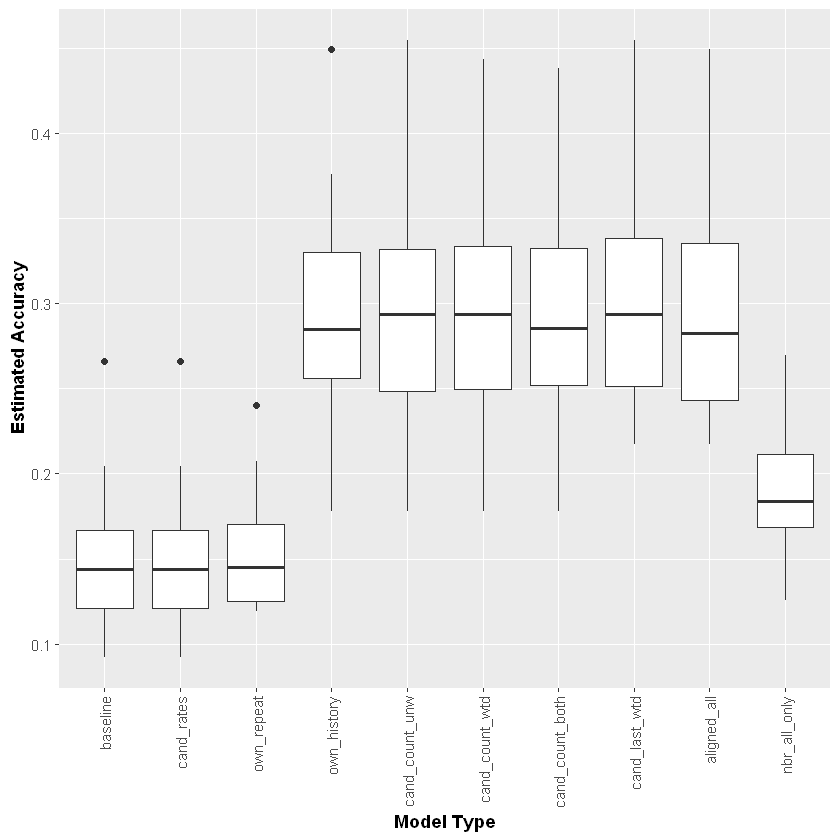

In [12]:
# Each box summarises the 11 males' held-out top-1 accuracies for one model type.
# Line = median, box = middle 50% of males, whiskers = range within 1.5 x IQR, points = outlying males.
accuracy_boxplot <- ablation_results %>%
    ggplot(aes(x = model, y = accuracy)) +
    geom_boxplot() +
    labs(x = "Model Type", y = "Estimated Accuracy") +
    theme(axis.title = element_text(face = "bold"),
          axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5))
print(accuracy_boxplot)

ggsave(file.path(RESULTS_DIR, paste0(MODEL_NAME, "_accuracy_boxplot.png")),
       plot = accuracy_boxplot, width = 8, height = 6, units = "in")

Confusion matrix (model set by `FINAL_MODEL`)

In [13]:
confusion_matrices <- event_results %>%
    filter(model == FINAL_MODEL) %>%
    group_split(focal_male) %>%
    set_names(map_chr(., ~ .x$focal_male[1])) %>%
    map(~ table(Prediction = .x$pred_type, Truth = .x$actual_type))
confusion_matrices

$DgTbO_M5
          Truth
Prediction  1  4  7  8 10 11 12 15 20 25 30 32 33 153 154 156
       1    5  0  2  0  0  0  0  0  1  0  0  0  4   0   0   0
       7    0  0  8  2  5  1  1  0  1  0  0  1  2   2   0   0
       8    1  1  1  8  3  5  0  0  2  1  0  3  5   1   0   0
       10   1  0  5  2  7  0  1  0  2  0  0  0  3   1   0   0
       11   0  0  0  0  0  0  0  0  1  0  0  0  0   0   0   0
       12   0  1  1  3  0  1  1  0  0  0  0  1  0   0   0   0
       20   8  1 10  2  7  2  1  0 19  0  0  1 13   6   0   0
       25   0  0  0  0  0  0  1  0  0  4  0  0  0   0   0   1
       32   0  1  0  3  0  0  0  0  0  0  0  2  1   0   0   0
       33  11  2 16  7  9  1  3  7  8  0  1  4 37  11   2   0
       153  4  1  5  3 12  2  0  1  6  0  0  1  6   7   0   0

$DgTbO_M6
          Truth
Prediction  1  4  6  7  8 10 11 12 15 20 25 30 32 33 153 155 159 161
       1    0  0  0  0  0  2  0  0  0  1  0  0  0  1   1   0   0   0
       4    0  2  0  1  1  1  0  1  0  0  0  0  0  2   0   0   0 

Macro precision and recall (as in notebook 06; classes that were never predicted or never occurred are left out of the average, as `yardstick` does)

In [14]:
macro_pr <- function(pred, truth) {
    recall    <- map_dbl(unique(truth), ~ mean(pred[truth == .x] == .x))
    precision <- map_dbl(unique(pred),  ~ mean(truth[pred == .x] == .x))
    c(macro_precision = mean(precision), macro_recall = mean(recall))
}
macro_metrics <- event_results %>%
    group_by(model, focal_male) %>%
    summarise(macro_precision = macro_pr(pred_type, actual_type)["macro_precision"],
              macro_recall    = macro_pr(pred_type, actual_type)["macro_recall"], .groups = "drop")
macro_metrics %>% filter(model == FINAL_MODEL)

model,focal_male,macro_precision,macro_recall
<chr>,<chr>,<dbl>,<dbl>
aligned_all,DgTbO_M5,0.2860278,0.1929852
aligned_all,DgTbO_M6,0.2106753,0.1252765
aligned_all,KLgK_M5,0.2636257,0.1884491
aligned_all,KRDg_M2,0.3259735,0.2587586
aligned_all,LbOW_M1,0.5159851,0.2560516
aligned_all,RRO_M6,0.2763705,0.1240476
aligned_all,RbDgY_M2,0.2600297,0.1878806
aligned_all,TbTbLg_M4,0.2299656,0.2059349
aligned_all,TbWY_M1,0.4444482,0.2533031


Coefficients (model set by `FINAL_MODEL`)

These replace notebook 06's variable-importance plots. Coefficients are per standard deviation of the feature (`estimate_std`), so they are comparable across features. A positive value means that a candidate is more likely to be chosen when the feature is larger. In `estimate_raw` the unit is the feature's own unit, so `exp(estimate_raw)` is the odds multiplier per unit.

# A tibble: 10 × 5
   term                     mean_estimate_std     se n_males_positive n_males
   <chr>                                <dbl>  <dbl>            <int>   <int>
 1 cand_trans_own_1                    0.748  0.0420               11      11
 2 cand_repeats_own_last_1            -0.601  0.0837                0      11
 3 cand_repeats_own_last_2            -0.497  0.0698                0      11
 4 cand_repeat_x_logtime_1             0.497  0.0815               10      11
 5 cand_n_songs_weighted               0.457  0.183                 8      11
 6 cand_n_songs_unweighted            -0.449  0.188                 3      11
 7 cand_repeat_x_logtime_2             0.417  0.0693               10      11
 8 cand_trans_own_2                    0.292  0.0494               10      11
 9 cand_nbr_last_1_weighted            0.269  0.0230               11      11
10 cand_nbr_last_2_weighted            0.0907 0.0162               10      11


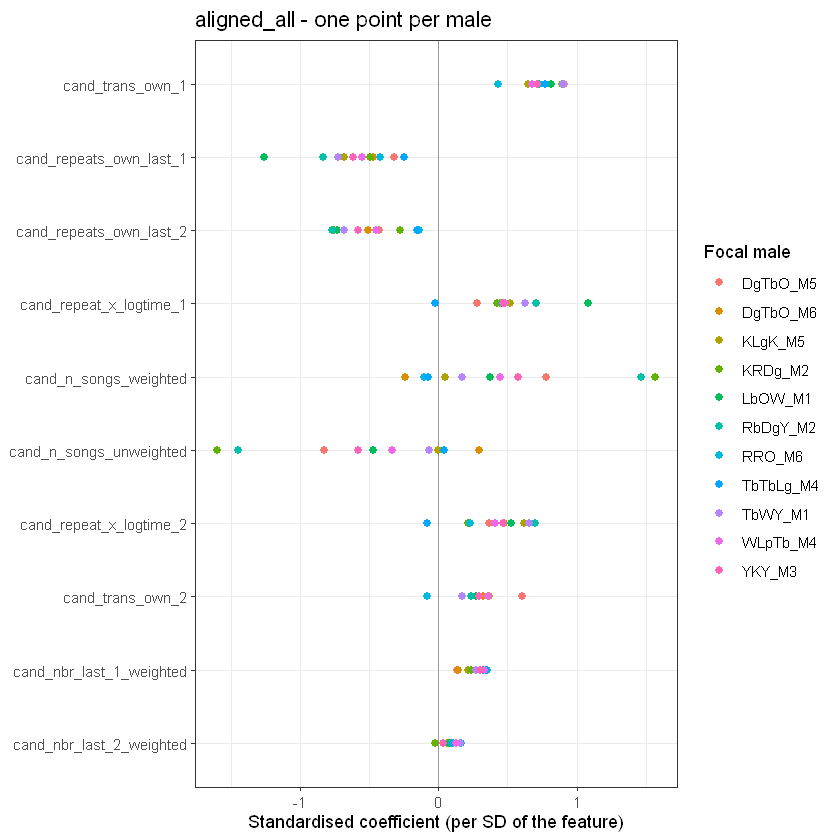

In [15]:
coef_summary <- coefficients_all %>%
    filter(model == FINAL_MODEL) %>%
    group_by(term) %>%
    summarise(mean_estimate_std = mean(estimate_std),
              se = sd(estimate_std) / sqrt(n()),
              n_males_positive = sum(estimate_std > 0),
              n_males = n(), .groups = "drop") %>%
    arrange(desc(abs(mean_estimate_std)))
print(coef_summary, n = Inf)

coefficients_all %>%
    filter(model == FINAL_MODEL) %>%
    mutate(term = factor(term, levels = rev(coef_summary$term))) %>%
    ggplot(aes(estimate_std, term)) +
    geom_vline(xintercept = 0, colour = "grey60") +
    geom_point(aes(colour = focal_male), size = 2) +
    labs(x = "Standardised coefficient (per SD of the feature)", y = NULL, colour = "Focal male",
         title = paste(FINAL_MODEL, "- one point per male")) +
    theme_bw()

Comparison with the random forest of notebook 06 (if its results were saved). The split is the same (same seed and events), so the held-out events are the same.

In [16]:
rf_path <- file.path(RESULTS_DIR, paste0(RF_MODEL_NAME, "_test_metrics.csv"))
if (file.exists(rf_path)) {
    rf <- read_csv(rf_path, show_col_types = FALSE) %>%
        select(focal_male, n_test_events_rf = n_test_events, accuracy_rf = accuracy,
               top3_recall_rf = top3_recall, mrr_rf = mean_reciprocal_rank)
    clogit_wide <- ablation_results %>%
        filter(model %in% unique(c("baseline", "own_history", FINAL_MODEL))) %>%
        select(focal_male, n_test_events, model, accuracy) %>%
        pivot_wider(names_from = model, values_from = accuracy, names_prefix = "accuracy_clogit_")
    comparison <- left_join(clogit_wide, rf, by = "focal_male") %>%
        mutate(same_test_events = n_test_events == n_test_events_rf)
    print(comparison, n = Inf, width = Inf)
    cat("\nMean accuracy, clogit", FINAL_MODEL, ":", round(mean(comparison[[paste0("accuracy_clogit_", FINAL_MODEL)]]), 4),
        "| notebook 06 RF:", round(mean(comparison$accuracy_rf), 4), "\n")
} else {
    message("No notebook 06 results found at ", rf_path)
}

No notebook 06 results found at data/2026_results/candidate_match_distance_weighted_window60_test_metrics.csv



Save results: CSV exports

One file per model, `<model name>_song_accuracies.csv`, with columns `ID, UST, estimated_accuracy, model, n`:

* `ID`: focal male (`DgTbO_M5` and `DgTbO_M6` are kept separate).
* `UST`: song type.
* `estimated_accuracy`: among the held-out events in which this male actually sang this song type, the share where the candidate with the highest predicted probability was that song type.
* `n`: number of observations (events) of this song type by this male in the data used for modelling (training and test).

Rows are ordered by ID, then by accuracy (highest first). Song types with no held-out events have no accuracy and are not listed.

The next cell writes one file per model, `<model name>_test_accuracies.csv`, with columns `ID, estimated_accuracy, model, n`. These accuracies are calculated across all held-out events for each male, without dividing by UST.

In [22]:
# Display names for the model files (edit freely; the file name is the label with punctuation turned into underscores)
MODEL_LABELS <- c(
    baseline        = "Baseline most common song",
    cand_rates      = "Song type rates",
    own_repeat      = "Own repeat",
    own_history     = "Own song history",
    cand_count_unw  = "Own history and neighbour counts",
    cand_count_wtd  = "Own history and weighted neighbour counts",
    cand_count_both = "Own history and both neighbour counts",
    cand_last_wtd   = "Own history and weighted neighbour last songs",
    aligned_all     = "All neighbour features",
    nbr_all_only    = "Neighbours only"
)

# Observations of each song type per male (training + test events)
n_obs <- map_dfr(designs, ~ tibble(ID = .x$focal_male, UST = .x$types, n = tabulate(.x$chosen, nbins = .x$K)))

song_accuracies <- event_results %>%
    group_by(model, ID = focal_male, UST = actual_type) %>%
    summarise(estimated_accuracy = mean(pred_type == actual_type), .groups = "drop") %>%
    left_join(n_obs, by = c("ID", "UST")) %>%
    mutate(model = unname(MODEL_LABELS[as.character(model)]), model_type = "Conditional Logit") %>%
    arrange(tolower(ID), desc(estimated_accuracy), UST) %>%
    select(ID, UST, estimated_accuracy, model, n)

walk(split(song_accuracies, song_accuracies$model), function(df) {
    file_name <- paste0("logit_", str_replace_all(df$model[1], "[^A-Za-z0-9]+", "_"), "_song_accuracies.csv")
    write_csv(df, file.path(RESULTS_DIR, file_name))
})

ablation_summary

model,mean_features_used,accuracy,random_baseline,top3_recall,mean_reciprocal_rank,mean_rank,mean_log_lik,pseudo_r2
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
baseline,0,0.1532328,0.04653498,0.3638480,0.3323932,6.143633,-2.632174,0.1450473
cand_rates,0,0.1532328,0.04653498,0.3638480,0.3323962,6.142508,-2.633209,0.1447002
own_repeat,2,0.1555622,0.04653498,0.3621994,0.3347995,6.081895,-2.624668,0.1473940
own_history,6,0.2953898,0.04653498,0.5626423,0.4791409,4.434907,-2.280263,0.2583883
cand_count_unw,7,0.2973365,0.04653498,0.5718387,0.4822082,4.366981,-2.266577,0.2628904
cand_count_wtd,7,0.2961234,0.04653498,0.5696862,0.4817177,4.359966,-2.265554,0.2632214
cand_count_both,8,0.2975152,0.04653498,0.5706855,0.4822571,4.356642,-2.266257,0.2629652
cand_last_wtd,8,0.3053573,0.04653498,0.5846928,0.4937072,4.173273,-2.220634,0.2778453
aligned_all,10,0.3016676,0.04653498,0.5887904,0.4925466,4.162907,-2.219786,0.2781501


In [23]:
# Overall held-out accuracy per male, without dividing by song type (UST)
test_accuracies <- event_results %>%
    group_by(model, ID = focal_male) %>%
    summarise(estimated_accuracy = mean(pred_type == actual_type),
              n = n(), .groups = "drop") %>%
    mutate(model = unname(MODEL_LABELS[as.character(model)])) %>%
    arrange(tolower(ID), desc(estimated_accuracy)) %>%
    select(ID, estimated_accuracy, model, n)

walk(split(test_accuracies, test_accuracies$model), function(df) {
    file_name <- paste0("logit_", str_replace_all(df$model[1], "[^A-Za-z0-9]+", "_"), "_test_accuracies.csv")
    write_csv(df, file.path(RESULTS_DIR, file_name))
})

test_accuracies

ID,estimated_accuracy,model,n
<chr>,<dbl>,<chr>,<int>
DgTbO_M5,0.2997118,Own song history,347
DgTbO_M5,0.2939481,Own history and neighbour counts,347
DgTbO_M5,0.2939481,Own history and weighted neighbour counts,347
DgTbO_M5,0.2939481,Own history and weighted neighbour last songs,347
DgTbO_M5,0.2853026,Own history and both neighbour counts,347
DgTbO_M5,0.2824207,All neighbour features,347
DgTbO_M5,0.2074928,Own repeat,347
DgTbO_M5,0.2046110,Baseline most common song,347
DgTbO_M5,0.2046110,Song type rates,347
